# Setup Guide: Multiclass Road Surface Damage Classification

**Dataset:** https://data.mendeley.com/datasets/697w4jkr2x/2 

## 1. Load the dataset

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42
DATA_DIR = Path("Dataset")
IMG_SIZE = 640
N_FOLDS = 5
VAL_FRACTION = 0.15

CLASS_NAMES = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())

rows = []
for class_id, class_name in enumerate(CLASS_NAMES):
    for path in sorted((DATA_DIR / class_name).iterdir()):
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({"path": str(path), "class_name": class_name, "class_id": class_id})

df = pd.DataFrame(rows)
print("Classes:", CLASS_NAMES)
print("Total images:", len(df))
df.head()

Classes: ['Crack', 'Pothole', 'Surface Erosion']
Total images: 1530


,path,class_name,class_id
0,Dataset/Crack/1.jpg,Crack,0
1,Dataset/Crack/10.jpg,Crack,0
2,Dataset/Crack/100.jpg,Crack,0
3,Dataset/Crack/1001.jpg,Crack,0
4,Dataset/Crack/1002.jpg,Crack,0


## 2. Class balance

class_name
Crack              478
Pothole            401
Surface Erosion    651


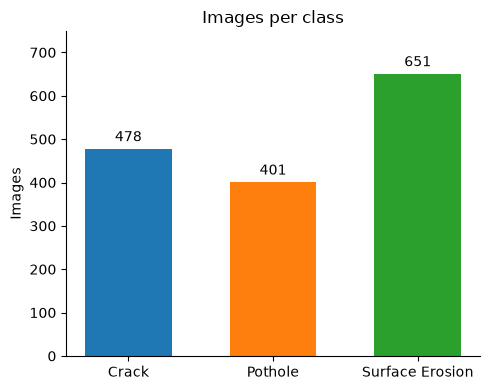

In [ ]:
counts = df["class_name"].value_counts().reindex(CLASS_NAMES)
print(counts.to_string())

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, width=0.6, color=["tab:blue", "tab:orange", "tab:green"])
ax.bar_label(bars, padding=3)
ax.set_title("Images per class")
ax.set_ylabel("Images")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. Image dimensions
Most images are 640×640. Some are not.

In [3]:
def image_size(path):
    with Image.open(path) as im:
        w, h = im.size
    return f"{w}x{h}"

df["size"] = df["path"].map(image_size)

print("Image sizes (width x height) per class:")
display(pd.crosstab(df["size"], df["class_name"]))

Image sizes (width x height) per class:


class_name,Crack,Pothole,Surface Erosion
size,,,
1040x780,0,0,2
640x640,478,397,592
720x1280,0,0,49
780x1040,0,4,8


## 4. Make every image 640×640 when loading
Images that aren't already 640×640 are **centre-cropped to a square, then resized**, so nothing gets stretched.

All three pipelines should load images with this same function, so everyone works with identical images.

In [ ]:
def load_image(path):
    # Load an image as RGB at IMG_SIZE x IMG_SIZE (centre-crop to square, then resize if needed).
    with Image.open(path) as im:
        img = im.convert("RGB")
    w, h = img.size
    if (w, h) != (IMG_SIZE, IMG_SIZE):
        side = min(w, h)
        left, top = (w - side) // 2, (h - side) // 2
        img = img.crop((left, top, left + side, top + side)).resize((IMG_SIZE, IMG_SIZE))
    return img


# Check the odd-sized images all come out at 640x640 after loading
odd = df[df["size"] != f"{IMG_SIZE}x{IMG_SIZE}"]
assert all(load_image(p).size == (IMG_SIZE, IMG_SIZE) for p in odd["path"])
print(f"Total images resized: {len(odd)}")
print(f"Resulting size: {IMG_SIZE}x{IMG_SIZE}")

Total images resized: 63
Resulting size: 640x640


## 5. Example images

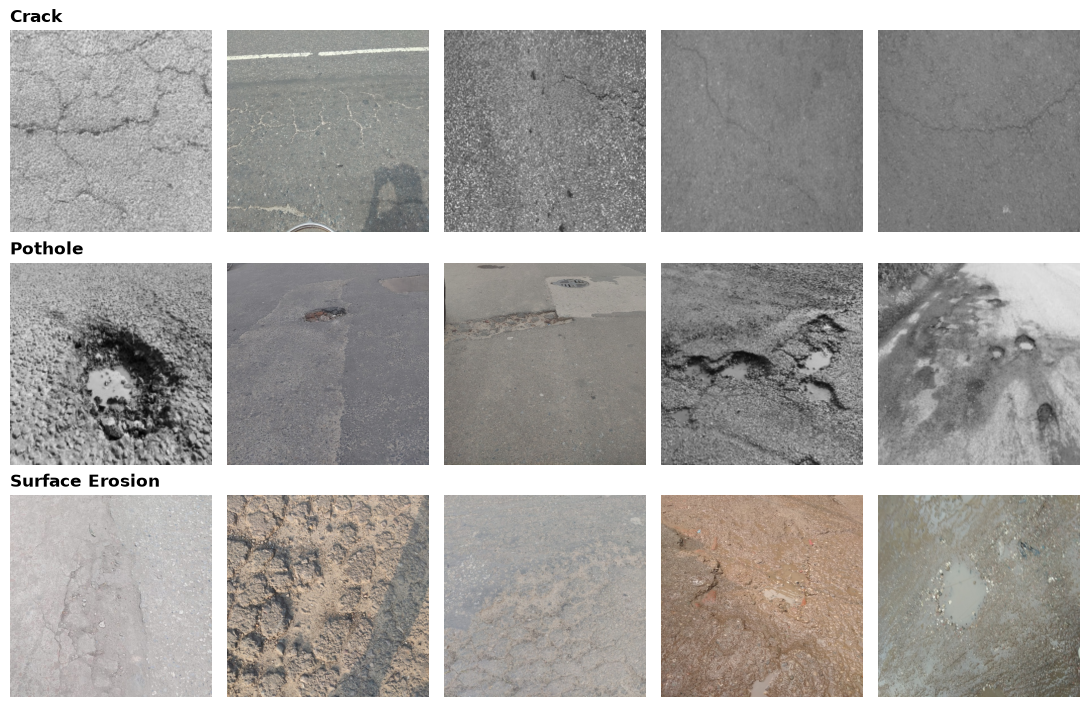

In [12]:
N = 5
fig, axes = plt.subplots(len(CLASS_NAMES), N, figsize=(2.2 * N, 2.4 * len(CLASS_NAMES)))
for i, name in enumerate(CLASS_NAMES):
    sample = df[df["class_name"] == name].sample(N, random_state=SEED)
    for ax, path in zip(axes[i], sample["path"]):
        ax.imshow(load_image(path))
        ax.axis("off")
    axes[i, 0].set_title(name, loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 6. train / val / test split
The dataset is small, so instead of one fixed split we can use **5-fold cross-validation**:

1. Every image is assigned to one of 5 **folds**.
2. In round *k*, fold *k* is the **test** set and the other 4 folds are used for training.
3. Those 4 training folds are split again into **85% train** and **15% val**.
4. Repeat for all 5 rounds, so every image is tested exactly once, then average the 5 test scores.

The fold numbers are saved to `folds.csv` and the val split uses a fixed seed, so everyone in the group uses the same train / val / test images.

In [6]:
df["fold"] = -1
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, test_idx) in enumerate(skf.split(df, df["class_id"])):
    df.loc[test_idx, "fold"] = fold

df[["path", "class_name", "class_id", "fold"]].to_csv("folds.csv", index=False)
print("Saved folds.csv")
display(pd.crosstab(df["class_name"], df["fold"], margins=True))

Saved folds.csv


fold,0,1,2,3,4,All
class_name,,,,,,
Crack,96,96,96,95,95,478
Pothole,80,80,80,81,80,401
Surface Erosion,130,130,130,130,131,651
All,306,306,306,306,306,1530


In [7]:
def get_split(df, k):
    # Return (train, val, test) for cross-validation round k.
    test = df[df["fold"] == k]
    rest = df[df["fold"] != k]
    train, val = train_test_split(rest, test_size=VAL_FRACTION, stratify=rest["class_id"], random_state=SEED)
    return train, val, test


summary = []
for k in range(N_FOLDS):
    train, val, test = get_split(df, k)
    summary.append({"round": k, "train": len(train), "val": len(val), "test": len(test)})
display(pd.DataFrame(summary).set_index("round"))

,train,val,test
round,,,
0,1040,184,306
1,1040,184,306
2,1040,184,306
3,1040,184,306
4,1040,184,306
